# Clase 6/11 — Procesamiento de señales

Continuación de las clases anteriores, incluida la [clase del 30/10](../Octubre/clase_30-10.ipynb).


## Preparación: cargar las clases anteriores

Los notebooks anteriores están en `notebooks/Octubre/`. Buscamos esa carpeta desde el directorio de trabajo y ejecutamos allí la clase del 30/10. Las cargas anidadas de las demás clases se resuelven desde `Octubre`; al terminar, restauramos el directorio de trabajo que tenía esta sesión, incluso si ocurre un error.

Esta carga ejecuta los ejemplos, gráficos y simulaciones de los notebooks anteriores, incluidos los barridos Monte Carlo: puede tardar bastante. Para ejecutar notebooks con `%run`, el entorno necesita `nbformat`.

En VS Code se puede iniciar desde la carpeta del notebook o desde la raíz del proyecto. En Colab se debe conservar la estructura `notebooks/Octubre` y `notebooks/Noviembre`, con los cinco notebooks en sus carpetas respectivas.


In [ ]:
from pathlib import Path
import os

directorio_inicial = Path.cwd()
# Admitimos como directorio de trabajo Noviembre, notebooks o la raíz del proyecto.
candidatos_octubre = [
    directorio_inicial.parent / "Octubre",
    directorio_inicial / "Octubre",
    directorio_inicial / "notebooks" / "Octubre",
]
carpeta_octubre = next((carpeta.resolve() for carpeta in candidatos_octubre
                        if (carpeta / "clase_30-10.ipynb").is_file()), None)
if carpeta_octubre is None:
    raise FileNotFoundError(
        "No se encontró notebooks/Octubre/clase_30-10.ipynb. "
        "Comprobá el directorio de trabajo y la estructura de carpetas."
    )

try:
    # Los %run anidados de octubre también necesitan esta carpeta como base.
    os.chdir(carpeta_octubre)
    get_ipython().run_line_magic("run", "./clase_30-10.ipynb")
finally:
    os.chdir(directorio_inicial)


## 16. Detección en frecuencia con ocho upchirps

Buscamos solamente el preámbulo de **8 upchirps de símbolo cero**, sin utilizar los 2.25 downchirps para la detección. Para cada comienzo candidato $\ell$ evaluamos ocho ventanas consecutivas de $N=2^{SF}$ muestras. Desplazamos el comienzo candidato una muestra a la vez, porque el receptor no sabe dónde empieza el preámbulo.

En cada ventana multiplicamos por un **downchirp de referencia del receptor** y aplicamos la FFT. Esta referencia es necesaria para hacer el dechirp; no son los downchirps de la trama que decidimos excluir. Si la ventana está alineada con un upchirp cero, el resultado ideal es constante y su FFT concentra la energía en el bin 0.

Para cada ventana calculamos:

$$Q=\frac{|D[0]|^2}{\sum_p |D[p]|^2}.$$

Una ventana perfecta da 1 y una ventana sin energía da 0. Para exigir que **las ocho** ventanas superen el umbral, usamos como puntuación de la secuencia el mínimo de sus ocho valores $Q$. El detector selecciona el candidato con el mayor de esos mínimos y declara detección si ese valor es al menos el umbral. No es una probabilidad ni un umbral óptimo.

Se conoce SF y B; el ejemplo utiliza un canal plano, sin errores de frecuencia ni de reloj. La puntuación basada en el bin cero no corrige esos desplazamientos. En nuestro modelo discreto el upchirp cero tiene periodicidad de medio símbolo, de modo que pueden existir picos secundarios o empates: en caso de empate `np.argmax` elige el primero. Usar solo los ocho upchirps no garantiza sincronización única ni autentica una trama. Para medir falsas alarmas y probabilidad de detección necesitamos muchas capturas.

Mirar el bin 0 después del dechirp se relaciona con correlacionar cada ventana con el chirp correspondiente. Aquí calculamos la FFT y evaluamos sus bins; la comparación con la estrategia temporal requiere pruebas estadísticas.


### Funciones del detector

`validar_concentracion_bin_cero` reúne las comprobaciones de entrada. `concentracion_bin_cero` la llama y calcula el puntaje de cada ventana usando la FFT. `detectar_preambulo_frecuencia` toma ocho valores separados por N muestras para cada inicio candidato y exige que todos alcancen el umbral. La captura se procesa por lotes para limitar el uso de memoria.


In [ ]:
def validar_concentracion_bin_cero(recibida, referencia, tamano_lote):
    """Valida captura, referencia y tamaño de lote para el cálculo."""
    if recibida.ndim != 1 or referencia.ndim != 1 or referencia.size == 0:
        raise ValueError("La captura y la referencia deben ser vectores; la referencia no puede estar vacía.")
    if recibida.size < referencia.size:
        raise ValueError("La captura debe contener al menos una ventana completa.")
    if not np.all(np.isfinite(recibida)) or not np.all(np.isfinite(referencia)):
        raise ValueError("Las muestras deben ser finitas.")
    if not isinstance(tamano_lote, (int, np.integer)) or tamano_lote < 1:
        raise ValueError("El tamaño de lote debe ser un entero positivo.")
    if not np.allclose(np.abs(referencia), 1):
        raise ValueError("La referencia de dechirp debe tener módulo uno.")


def concentracion_bin_cero(recibida, referencia, tamano_lote=256):
    """Puntaje espectral de cada ventana frente a un chirp de referencia."""
    recibida = np.asarray(recibida, dtype=complex)
    referencia = np.asarray(referencia, dtype=complex)
    validar_concentracion_bin_cero(recibida, referencia, tamano_lote)

    M = referencia.size                                                 # Tamaño de la ventana de análisis (dechirp).
    ventanas = np.lib.stride_tricks.sliding_window_view(recibida, M)    # Dividimos la captura en ventanas de tamaño M (avanzando de a 1 muestra).
    puntajes = np.zeros(len(ventanas))                                  # Puntaje espectral (Q) de cada ventana frente a la referencia.
    
    for inicio in range(0, len(ventanas), tamano_lote):                 # Procesamos en lotes para ahorrar memoria.

        fin = min(inicio + tamano_lote, len(ventanas))                  # Fin del lote.
        
        dechirp = ventanas[inicio:fin] * referencia                     # Aplicamos el dechirp a cada ventana.
        espectros = aplicar_fft(dechirp)                                # Aplicamos FFT normalizada en cada fila.
        
        energia = np.sum(np.abs(espectros) ** 2, axis=1)                # Calculamos la energia de todos los bins
        pico_cero = np.abs(espectros[:, 0]) ** 2                        # Calculamos la energia del bin cero de cada ventana

        np.divide(pico_cero, energia, out=puntajes[inicio:fin], where=energia > 0)  # Calculamos Q de cada ventana y se guarda en puntajes (sin dividir por cero)

    return np.clip(puntajes, 0, 1)      # devolvemos puntajes Q 


def detectar_preambulo_frecuencia(recibida, SF, B, umbral=0.8, tamano_lote=256):
    """Busca ocho upchirps usando dechirp y FFT, sin analizar la trama posterior."""
    if not isinstance(SF, (int, np.integer)) or SF < 2:
        raise ValueError("SF debe ser un entero mayor o igual a 2.")
    if not np.isscalar(umbral) or not np.isrealobj(umbral) or not 0 < umbral <= 1:
        raise ValueError("El umbral debe estar entre 0 (excluido) y 1.")

    recibida = np.asarray(recibida, dtype=complex)
    N = 2 ** SF
    longitud_preambulo = 8 * N
    
    if recibida.ndim != 1 or recibida.size < longitud_preambulo:
        raise ValueError("La captura debe ser un vector con al menos ocho símbolos completos.")

    up_unitario = modular_simbolo(0, SF, B, muestras_por_muestra=1)[0] * np.sqrt(N) 
    referencia_dechirp = np.conj(up_unitario)                                   # Definimos un Downchirp para hacer el dechirp.
    q_up = concentracion_bin_cero(recibida, referencia_dechirp, tamano_lote)    # Calculamos el puntaje espectral (Q) de cada ventana.

    cantidad_candidatos = recibida.size - longitud_preambulo + 1        # Aseguramos que la ultima ventana tenga al menos ocho símbolos completos.
    evidencias_up = np.stack([
        q_up[j * N:j * N + cantidad_candidatos] for j in range(8)       # Agrupamos los Q de las ocho ventanas de upchirps consecutivas (cada una de tamaño N)
    ])                                                                  # filas: cada upchirp, columnas: cada ventana de tamaño N.
    
    # El mínimo supera el umbral solo si las ocho ventanas lo superan.
    puntuacion = np.min(evidencias_up, axis=0)          # Tomamos el minimo valor de cada columna 
    indice_maximo = int(np.argmax(puntuacion))          # Buscamos el indice de la columna con el valor máximo de puntuacion
    maximo = float(puntuacion[indice_maximo])           # Buscamos el valor máximo de puntuacion
    detectado = maximo >= umbral                        # Si el máximo supera el umbral, consideramos que se detectó un preámbulo.

    return {
        "detectado": detectado,
        "inicio_preambulo": indice_maximo if detectado else None,
        "indice_maximo": indice_maximo,
        "fin_upchirps": indice_maximo + longitud_preambulo if detectado else None,
        "puntuacion_maxima": maximo,
        "puntuacion": puntuacion,
        "evidencias_up": evidencias_up,
        "longitud_preambulo": longitud_preambulo,
        "umbral": umbral,
    }


### Prueba con una trama desplazada

Reutilizamos las capturas ideal y ruidosa de la clase anterior. Para detectar, la función usa únicamente las muestras que corresponden a los ocho upchirps para cada candidato. La captura de ejemplo también contiene el resto de la trama, pero no se emplea una plantilla de downchirps. El `RETARDO_PRUEBA` se consulta solo después, para comprobar el resultado.


In [7]:
UMBRAL_FRECUENCIA = 0.8

resultado_frecuencia_ideal = detectar_preambulo_frecuencia(
    captura_ideal, SF_TRAMA, B_TRAMA, umbral=UMBRAL_FRECUENCIA
)
resultado_frecuencia_ruido = detectar_preambulo_frecuencia(
    captura_ruidosa, SF_TRAMA, B_TRAMA, umbral=UMBRAL_FRECUENCIA
)

print(f"Inicio real de prueba: muestra {RETARDO_PRUEBA}")
for nombre, resultado in (("Sin ruido", resultado_frecuencia_ideal),
                          ("Con ruido", resultado_frecuencia_ruido)):
    print(f"{nombre}: detectado={resultado['detectado']}; "
          f"menor concentración de los 8 upchirps={resultado['puntuacion_maxima']:.4f}; "
          f"inicio estimado={resultado['inicio_preambulo']}")

# Comprobación para esta captura ideal; no implica sincronización perfecta en general.
assert resultado_frecuencia_ideal["inicio_preambulo"] == RETARDO_PRUEBA
assert np.isclose(resultado_frecuencia_ideal["puntuacion_maxima"], 1)


Inicio real de prueba: muestra 853
Sin ruido: detectado=True; menor concentración de los 8 upchirps=1.0000; inicio estimado=853
Con ruido: detectado=True; menor concentración de los 8 upchirps=0.9033; inicio estimado=853


### Puntuación y FFT de los upchirps

Arriba se muestra, para cada inicio candidato, el menor de los ocho puntajes espectrales. La línea horizontal es el umbral; la vertical marca el inicio real solo para verificar la simulación.

En el centro se muestran los ocho puntajes de la secuencia elegida en la captura ruidosa. Abajo se muestra la FFT del primer upchirp de esa secuencia después del dechirp. La referencia usada para el dechirp se genera localmente en el receptor y no representa un downchirp recibido de la trama. Si no hay detección, los dos últimos gráficos quedan vacíos.


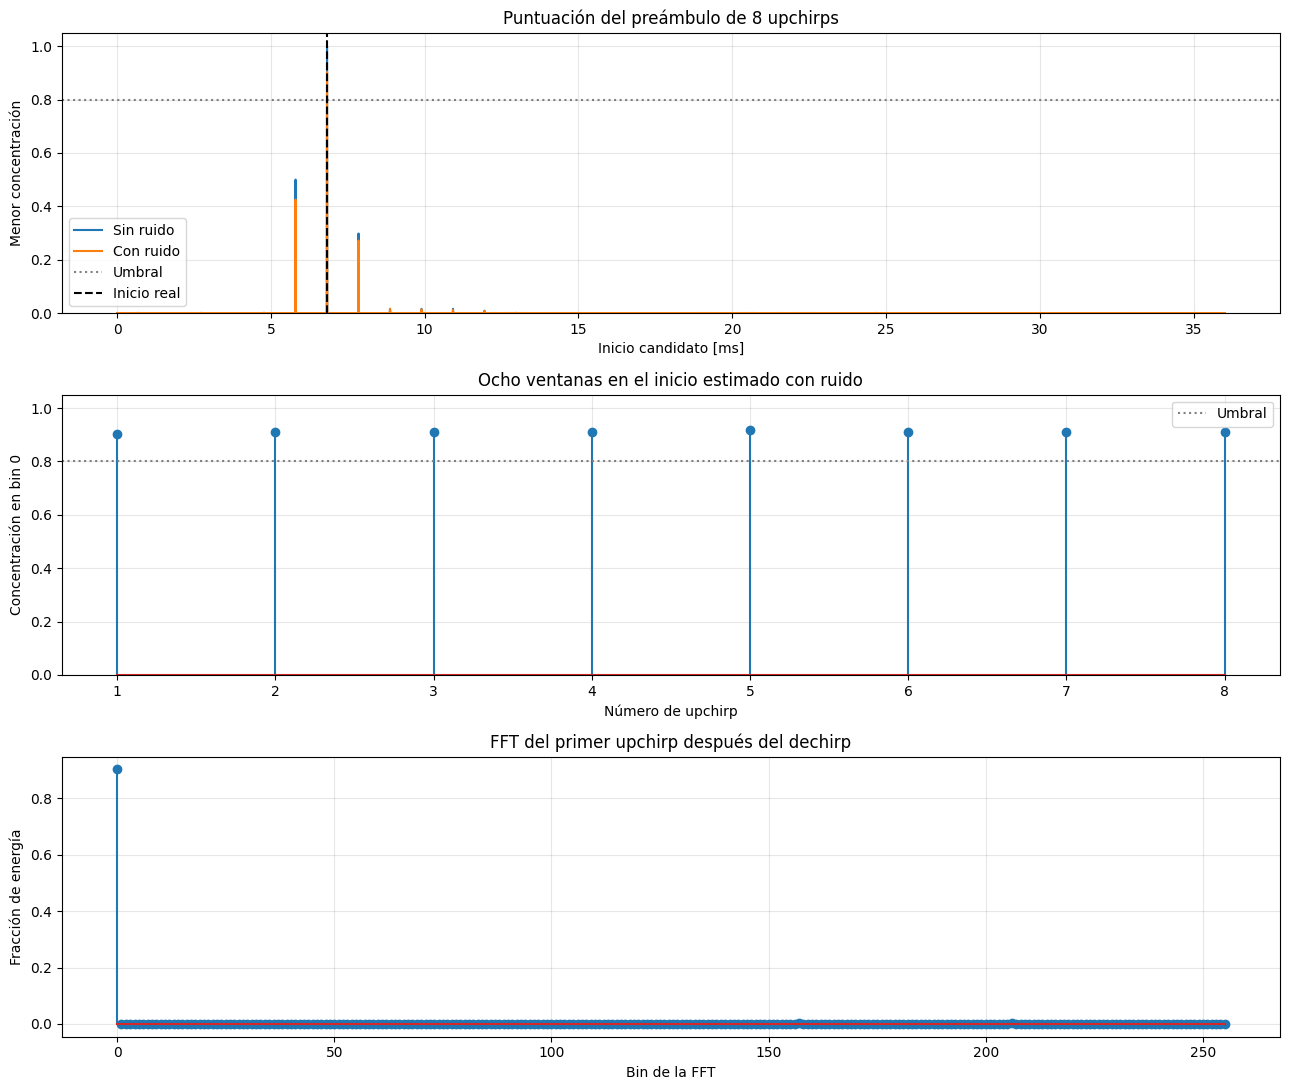

In [8]:
fig_deteccion_frecuencia, ejes_freq = plt.subplots(3, 1, figsize=(13, 11))
for nombre, resultado in (("Sin ruido", resultado_frecuencia_ideal),
                          ("Con ruido", resultado_frecuencia_ruido)):
    tiempos = np.arange(resultado["puntuacion"].size) / B_TRAMA * 1000
    ejes_freq[0].plot(tiempos, resultado["puntuacion"], label=nombre)
ejes_freq[0].axhline(UMBRAL_FRECUENCIA, color="gray", linestyle=":", label="Umbral")
ejes_freq[0].axvline(RETARDO_PRUEBA / B_TRAMA * 1000, color="black", linestyle="--", label="Inicio real")
ejes_freq[0].set(title="Puntuación del preámbulo de 8 upchirps",
                 xlabel="Inicio candidato [ms]", ylabel="Menor concentración")
ejes_freq[0].set_ylim(0, 1.05)
ejes_freq[0].legend()

if resultado_frecuencia_ruido["detectado"]:
    comienzo = resultado_frecuencia_ruido["inicio_preambulo"]
    ocho_valores = resultado_frecuencia_ruido["evidencias_up"][:, comienzo]
    ejes_freq[1].stem(np.arange(1, 9), ocho_valores)
    ejes_freq[1].axhline(UMBRAL_FRECUENCIA, color="gray", linestyle=":", label="Umbral")
    ejes_freq[1].legend()

    up_unitario = modular_simbolo(0, SF_TRAMA, B_TRAMA, muestras_por_muestra=1)[0] * np.sqrt(N_TRAMA)
    ventana = captura_ruidosa[comienzo:comienzo + N_TRAMA]
    espectro = aplicar_fft(ventana * np.conj(up_unitario))
    potencia = np.abs(espectro) ** 2
    if potencia.sum() > 0:
        ejes_freq[2].stem(np.arange(N_TRAMA), potencia / potencia.sum())
else:
    for eje in ejes_freq[1:]:
        eje.text(0.5, 0.5, "No se detectó una secuencia de ocho upchirps.",
                 transform=eje.transAxes, ha="center")

ejes_freq[1].set(title="Ocho ventanas en el inicio estimado con ruido",
                 xlabel="Número de upchirp", ylabel="Concentración en bin 0")
ejes_freq[1].set_xticks(np.arange(1, 9))
ejes_freq[1].set_ylim(0, 1.05)
ejes_freq[2].set(title="FFT del primer upchirp después del dechirp",
                 xlabel="Bin de la FFT", ylabel="Fracción de energía")
for eje in ejes_freq:
    eje.grid(True, alpha=0.3)
fig_deteccion_frecuencia.tight_layout()
plt.show()
